# Example axisymmetric inductor with solid copper current excitation

This notebook builds the model entirely from an in-memory versioned JSON-style dictionary, meshes it with Gmsh, and solves the axisymmetric A-phi frequency-domain problem. The copper model uses a ring voltage source $E_phi=V/(2*pi*r)$ and a prescribed total-current constraint. This captures axisymmetric skin redistribution; it does not claim non-axisymmetric proximity effects, which require a full 3-D or coupled scalar-potential formulation.

In [ ]:
%load_ext autoreload
%autoreload 2
from pathlib import Path
import json
import sys
import numpy as np
import matplotlib.pyplot as plt

REPOSITORY_ROOT = Path.cwd().resolve()
if not (REPOSITORY_ROOT / 'fem').is_dir():
    REPOSITORY_ROOT = REPOSITORY_ROOT.parent
if str(REPOSITORY_ROOT) not in sys.path:
    sys.path.insert(0, str(REPOSITORY_ROOT))

from dataclasses import asdict

from model import (
    AirGapSpec, Constructor, CoreSpec, InsulationSpec, Material,
    MeshSettings, OutputSettings, RectangularConductor, RoundConductor,
    SolverSettings, WindingLayer, WindingSpec, load,
)
from fem import (
    COPPER_CONDUCTIVITY_AT_20C_S_PER_M,
    build_mesh,
    FrequencyDomainResult,
    solve_frequency_domain,
    integrated_current,
    copper_loss,
    inductance,
    magnetic_flux_density,
    magnetic_field_intensity,
    winding_flux_linkage,
    winding_voltages,
    average_abs_current_density,
    compare_domainc_blocks,
    meeker_litz_properties,
    winding_copper_losses,
    core_losses,
    winding_litz_losses,
    build_result_report,
    PhysicalField, plot_mesh, plot_physical_field,
    complex_relative_permeability,
    core_loss_density,
)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Define the model

All dimensions are in metres. The 14 conductor centres reproduce the supplied example geometry.

In [ ]:
FREQUENCY_HZ = 900_000.0
CURRENT_A = 4.5
CORE_RELATIVE_PERMEABILITY = 1500.0
CORE_LOSS_ANGLE_DEG = 5.0
CORE_CONDUCTIVITY = 0.6
CORE_RELATIVE_PERMITTIVITY = 100_000.0
CORE_PERMITTIVITY_LOSS_ANGLE_DEG = 25.0
CONDUCTOR_RADIUS_M = 0.0013
USE_LITZ = False
LITZ_NUMBER_STRANDS = 150
LITZ_STRAND_RADIUS_M = 100e-6
# Coarse away from physics-critical boundaries; adaptive fields refine the
# core corners, air-gap boundary, and conductor geometry below.
MESH_SIZE_M = 0.0008
# Moderate conductor-boundary, core-corner, and air-gap refinement are
# enabled by default. Solid conductors additionally receive skin-depth
# refinement; homogenized Litz conductors do not.
SKIN_DEPTH_M = np.sqrt(
    2.0
    / (
        2.0
        * np.pi
        * FREQUENCY_HZ
        * 4e-7
        * np.pi
        * COPPER_CONDUCTIVITY_AT_20C_S_PER_M
    )
)
CONDUCTOR_MESH_SIZE_M = None if USE_LITZ else SKIN_DEPTH_M / 2.0

# Build the same 14-turn model through the reusable constructor module.
conductor = RoundConductor(
    "round_copper",
    radius=CONDUCTOR_RADIUS_M,
    material="copper",
    construction="litz" if USE_LITZ else "solid",
    strands=LITZ_NUMBER_STRANDS if USE_LITZ else None,
    strand_diameter=2.0 * LITZ_STRAND_RADIUS_M if USE_LITZ else None,
)
core = CoreSpec(
    name="core", material="core",
    outer_radius=0.019943733351606967,
    outer_half_height=0.018475,
    window_inner_radius=0.00745,
    window_outer_radius=0.0185,
    window_half_height=0.01475,
    core_type="Single",
)
insulation = InsulationSpec(
    c2w_left=0.003,
    c2w_right=0.00235,
    c2w_top=0.0073,
    c2w_bottom=0.001,
    w2w=0.0005,
)
inductor_winding = Constructor.place_winding(
    core=core,
    insulation=insulation,
    name="primary",
    conductor=conductor,
    circuit="primary",
    turns=14,
    radial_columns=2,
    current=CURRENT_A,
    traversal="inside2outside-bottom2top",
)
model = Constructor(
    core=core,
    windings=(inductor_winding,),
    air_gaps=(AirGapSpec(
        "center_gap", 0.003725, 0.0, 0.00745, 0.0005
    ),),
    insulation=insulation,
    metadata={"name": "example inductor"},
).build()
model.materials = [
    Material("core", relative_permeability=CORE_RELATIVE_PERMEABILITY, permeability_loss_angle_deg=CORE_LOSS_ANGLE_DEG, conductivity=CORE_CONDUCTIVITY, relative_permittivity=CORE_RELATIVE_PERMITTIVITY, permittivity_loss_angle_deg=CORE_PERMITTIVITY_LOSS_ANGLE_DEG),
    Material("air", relative_permeability=1.0),
    Material("copper", relative_permeability=1.0, conductivity=COPPER_CONDUCTIVITY_AT_20C_S_PER_M),
]
model.metadata.units = "m"
model.mesh = MeshSettings(max_size=MESH_SIZE_M, order=1)
model.solver = SolverSettings(type="axisymmetric_frequency_domain")
model.output = OutputSettings(fields=["A_phi", "B"])
model.excitation.frequency = FREQUENCY_HZ
model.excitation.circuits = {"primary": CURRENT_A}
model_data = asdict(model)
model_data.pop("_legacy", None)
assert len(model.windings[0].turns) == 14
model

FEMModel(schema='pyMagBEM', version=1, metadata=Metadata(name='example inductor', description='', author='', units='m', extra={'name': 'example inductor'}), geometry=Geometry(coordinate_system='axisymmetric_rz', core=Region(name='core', material='core', corners=[[0.0, -0.018475], [0.019943733351606967, -0.018475], [0.0, 0.018475], [0.019943733351606967, 0.018475]], center=None, size=None, extra={'core_type': 'Single', 'insulation_mm': {'c2w_left': 3.0, 'c2w_right': 2.35, 'c2w_top': 7.3, 'c2w_bottom': 1.0, 'w2w': 0.5}}), air_gaps=[Region(name='center_gap', material='air', corners=[], center=[0.003725, 0.0], size=[0.00745, 0.0005], extra={})], shunts=[], winding_window=Region(name='winding_window', material='air', corners=[[0.00745, -0.01475], [0.0185, -0.01475], [0.00745, 0.01475], [0.0185, 0.01475]], center=None, size=None, extra={}), extra={'name': 'example inductor'}), materials=[Material(name='core', relative_permeability=1500.0, permeability_loss_angle_deg=5.0, conductivity=0.6, re

In [15]:
# Save the model used by this notebook as a reusable JSON file.
SIMULATION_DIR = REPOSITORY_ROOT / 'notebooks' / 'sim'
SIMULATION_DIR.mkdir(parents=True, exist_ok=True)
MODEL_JSON = SIMULATION_DIR / 'example_inductor_generated.json'
MODEL_JSON.write_text(json.dumps(model_data, indent=2) + '\n', encoding='utf-8')
print(f'Saved model to {MODEL_JSON}')


Saved model to C:\Users\tpiepe\Repositories\pyMagBEM\notebooks\sim\example_inductor_generated.json


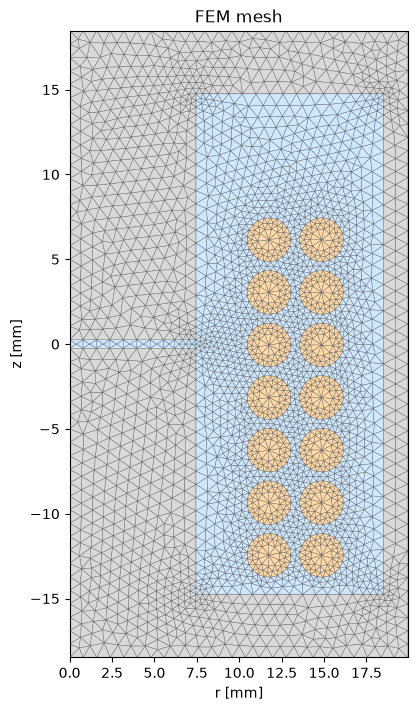

Frequency-domain solver timing (top tasks):
  matrix assembly: 0.490 s (93.5%)
  current-density reconstruction: 0.018 s (3.5%)
  sparse system construction and solve: 0.015 s (3.0%)
Frequency: 900,000 Hz
Current: 4.500 A
Mesh: 2909 nodes, 5672 triangles
Average |J| conductor 0: 5.628e+06 A/mÂ² (I/A = 8.476e+05 A/mÂ²)
Maximum |J| conductor 0: 1.680e+07 A/mÂ²
Current constraint error: 3.022e-08 A
Solid loss per turn: [0.14990711790876432, 0.05408099095333659, 0.11559048018057459, 0.2554607656717623, 0.5161488833143134, 0.1938425381694262, 0.2476018599031285, 0.8147341867615037, 1.161823515286162, 0.2225403477982524, 0.10450710034620417, 0.40356444984662077, 0.17452541273850317, 0.05947813386780862] W
Solid winding loss: 4.4738 W
Core magnetic loss: 50.6922 W
Core electrical loss: 66.7372 W
Core total loss: 117.4294 W
Flux-linkage inductance magnitude: 90.4647 ÂµH
Flux-linkage inductance phase: -1.38Â°
conductor_0 voltage: 166.6726 V (88.57Â°)
conductor_1 voltage: 166.8419 V (88.57Â°)
co

In [ ]:
mesh = build_mesh(
    model,
    max_size=MESH_SIZE_M,
    conductor_size=CONDUCTOR_MESH_SIZE_M,
)
fig_mesh, ax_mesh = plt.subplots(figsize=(10, 7), constrained_layout=True)
plot_mesh(mesh, ax=ax_mesh)
plt.show()
litz_properties = (
    meeker_litz_properties(
        FREQUENCY_HZ,
        strand_diameter=2.0 * LITZ_STRAND_RADIUS_M,
        fill_factor=conductor.fill_factor,
    )
    if USE_LITZ else None
)
solver_timing = {}
solve_result = solve_frequency_domain(
    mesh,
    frequency=FREQUENCY_HZ,
    currents=CURRENT_A,
    relative_permeability={'core': complex_relative_permeability(CORE_RELATIVE_PERMEABILITY, CORE_LOSS_ANGLE_DEG)},
    conductivity=COPPER_CONDUCTIVITY_AT_20C_S_PER_M,
    phasor_convention='cosine',
    return_voltages=not USE_LITZ,
    current_modes={"primary": "fixed_current_density"} if USE_LITZ else "total_current",
    fixed_current_density={"primary": CURRENT_A / integrated_current(mesh, np.ones(len(mesh.triangles)), "conductor_0").real} if USE_LITZ else None,
    litz_properties={"primary": litz_properties} if litz_properties else None,
    timing=solver_timing,
)
if USE_LITZ:
    a_phi, solved_density = solve_result
    turn_voltages = {}
else:
    a_phi, solved_density, turn_voltages = solve_result

result = FrequencyDomainResult.from_solution(
    model, mesh, a_phi, solved_density,
    frequency_hz=FREQUENCY_HZ, turn_voltages=turn_voltages,
)
timing_total = sum(solver_timing.values())
print('Frequency-domain solver timing (top tasks):')
for task, seconds in sorted(solver_timing.items(), key=lambda item: item[1], reverse=True):
    share = 100.0 * seconds / timing_total if timing_total else 0.0
    print(f'  {task}: {seconds:.3f} s ({share:.1f}%)')
flux_density = magnetic_flux_density(mesh, a_phi)
field_intensity = magnetic_field_intensity(
    mesh, a_phi, relative_permeability={"core": CORE_RELATIVE_PERMEABILITY}
)
current_density = solved_density
flux_density_magnitude = np.linalg.norm(flux_density, axis=1)
solid_losses = None
if not USE_LITZ:
    solid_losses = winding_copper_losses(
        mesh, solved_density, conductivity=COPPER_CONDUCTIVITY_AT_20C_S_PER_M
    )
core_mag_loss_w, core_el_loss_w, core_total_loss_w = core_losses(
    mesh, field_intensity, FREQUENCY_HZ, a_phi=a_phi,
    relative_permeability=CORE_RELATIVE_PERMEABILITY,
    loss_angle_deg=CORE_LOSS_ANGLE_DEG, conductivity=CORE_CONDUCTIVITY,
    relative_permittivity=CORE_RELATIVE_PERMITTIVITY,
    permittivity_loss_angle_deg=CORE_PERMITTIVITY_LOSS_ANGLE_DEG,
)
litz_losses = None
if litz_properties is not None:
    litz_losses = winding_litz_losses(
        mesh, solved_density, field_intensity, FREQUENCY_HZ,
        strand_diameter=2.0 * LITZ_STRAND_RADIUS_M,
        fill_factor=conductor.fill_factor,
    )
current_error_a = abs(integrated_current(mesh, solved_density['conductor_0'], 'conductor_0') - CURRENT_A)
flux_linkage_wb = winding_flux_linkage(mesh, a_phi, CURRENT_A)
linkage_inductance_h = flux_linkage_wb / CURRENT_A

terminal_voltages = {} if USE_LITZ else winding_voltages(
    mesh, a_phi, solved_density, CURRENT_A, FREQUENCY_HZ, phasor_convention='cosine'
)
result_report = build_result_report(
    model,
    mesh,
    frequency_hz=FREQUENCY_HZ,
    currents_a={"primary": CURRENT_A},
    current_densities=solved_density,
    flux_density=flux_density,
    inductance_h={"primary": linkage_inductance_h},
    solid_losses={"primary": solid_losses} if solid_losses is not None else None,
    litz_losses={"primary": litz_losses} if litz_losses is not None else None,
    core_losses={"core": (core_mag_loss_w, core_el_loss_w, core_total_loss_w)},
    turn_voltages=turn_voltages,
    terminal_voltages=terminal_voltages,
)
result_report.print()
RESULT_JSON = SIMULATION_DIR / 'result.json'
result_report.write_json(RESULT_JSON)
print(f'Saved result report to {RESULT_JSON}')

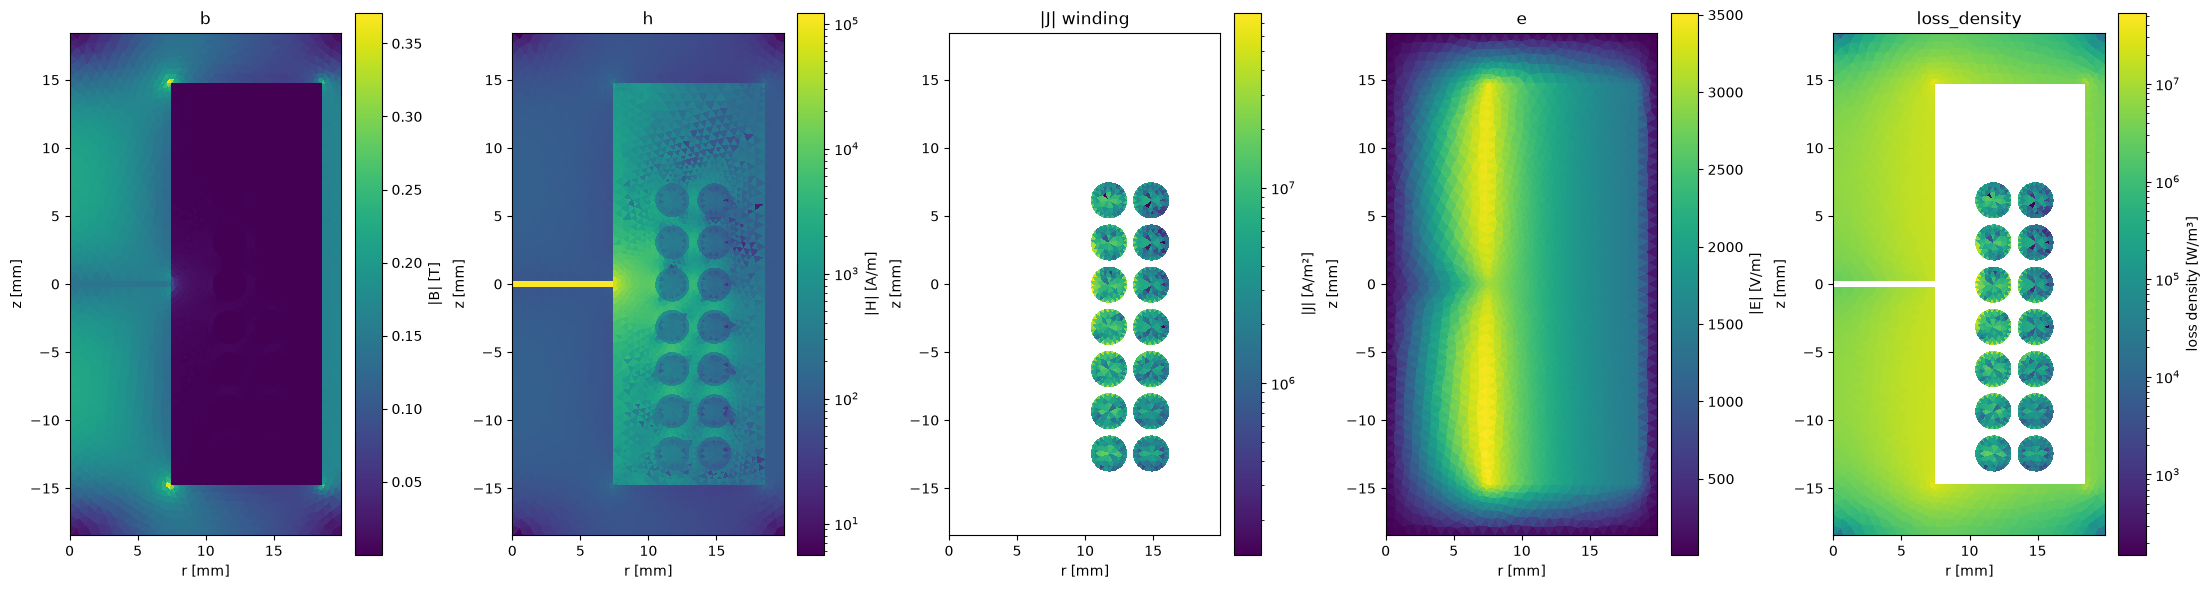

In [17]:
fig, axes = plt.subplots(1, 5, figsize=(22, 6), constrained_layout=True)
plot_requests = [
    (PhysicalField.B, {}),
    (PhysicalField.H, {}),
    (PhysicalField.J, {"domains": "winding"}),
    (PhysicalField.E, {}),
    (PhysicalField.LOSS_DENSITY, {"litz_properties": litz_properties}),
]
for axis, (physical_field, kwargs) in zip(axes.flat, plot_requests):
    scale = "log" if physical_field in {PhysicalField.H, PhysicalField.J, PhysicalField.LOSS_DENSITY} else "linear"
    result.plot_physical_field(physical_field, ax=axis, color_scale=scale, **kwargs)
    axis.set_title("|J| winding" if physical_field is PhysicalField.J else physical_field.value)
for axis in axes.flat[len(plot_requests):]:
    axis.set_visible(False)
plt.show()